In [ ]:
#load dataset
import pandas as pd
import numpy as np

df = pd.read_csv('patient_records_dataset.csv')

In [2]:
df.head(5)

,patient_id,date_of_birth,gender,height_cm,weight_kg,blood_type,systolic_bp_mmHg,diastolic_bp_mmHg,fasting_blood_sugar_mg_dl,cholesterol_mg_dl,daily_salt_intake_g,activity_hours_per_week,smoker_status,hypertension_diagnosis
0,PAT-1001,17/03/1946,Male,166.5,80.2,O+,164,97,113.0,244.7,13.2,0,Non-Smoker,1
1,PAT-1002,08/05/1992,Female,156.8,57.8,O+,137,85,97.6,178.5,9.5,1,Non-Smoker,1
2,PAT-1003,11/04/1976,Female,165.9,85.9,O+,143,81,107.5,184.8,12.1,3,Non-Smoker,1
3,PAT-1004,03/03/1980,Female,153.7,69.6,A+,136,82,107.1,225.2,6.7,2,Non-Smoker,0
4,PAT-1005,27/10/1996,Male,180.9,89.0,O+,143,85,104.0,174.4,8.0,10,Former Smoker,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   patient_id                 500 non-null    object 
 1   date_of_birth              500 non-null    object 
 2   gender                     500 non-null    object 
 3   height_cm                  495 non-null    float64
 4   weight_kg                  500 non-null    float64
 5   blood_type                 498 non-null    object 
 6   systolic_bp_mmHg           500 non-null    int64  
 7   diastolic_bp_mmHg          500 non-null    int64  
 8   fasting_blood_sugar_mg_dl  500 non-null    float64
 9   cholesterol_mg_dl          500 non-null    float64
 10  daily_salt_intake_g        500 non-null    float64
 11  activity_hours_per_week    500 non-null    int64  
 12  smoker_status              500 non-null    object 
 13  hypertension_diagnosis     500 non-null    int64  

In [4]:
df.describe()

,height_cm,weight_kg,systolic_bp_mmHg,diastolic_bp_mmHg,fasting_blood_sugar_mg_dl,cholesterol_mg_dl,daily_salt_intake_g,activity_hours_per_week,hypertension_diagnosis
count,495.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,167.969293,77.350400,144.128000,89.238000,111.795200,209.033000,9.216200,1.740000,0.790000
std,9.981949,16.479724,9.957405,7.651827,12.233453,30.118047,3.452581,1.700053,0.407716
min,138.500000,36.000000,117.000000,71.000000,78.200000,144.700000,3.000000,0.000000,0.000000
25%,160.950000,64.975000,137.000000,84.000000,103.475000,191.175000,6.300000,0.000000,1.000000
50%,167.000000,76.350000,144.000000,89.000000,111.800000,206.400000,9.600000,1.000000,1.000000
75%,174.750000,88.600000,151.000000,95.000000,120.200000,221.950000,12.225000,3.000000,1.000000
max,196.600000,125.600000,171.000000,113.000000,149.000000,380.600000,15.000000,10.000000,1.000000


In [ ]:
#check for duplicates
df.duplicated().sum()

np.int64(0)

In [5]:
#check for missing values
df.isnull().sum()

patient_id                   0
date_of_birth                0
gender                       0
height_cm                    5
weight_kg                    0
blood_type                   2
systolic_bp_mmHg             0
diastolic_bp_mmHg            0
fasting_blood_sugar_mg_dl    0
cholesterol_mg_dl            0
daily_salt_intake_g          0
activity_hours_per_week      0
smoker_status                0
hypertension_diagnosis       0
dtype: int64

There are 5 missing values in the height_cm column and 2 missing values in blood_type columns


Handle missing values in height column
-

In [84]:
#get rows with missing values
df[df.isnull().any(axis=1)]

,patient_id,date_of_birth,gender,height_cm,weight_kg,blood_type,systolic_bp_mmHg,diastolic_bp_mmHg,fasting_blood_sugar_mg_dl,cholesterol_mg_dl,daily_salt_intake_g,activity_hours_per_week,smoker_status,hypertension_diagnosis
7,PAT-1008,06/08/2003,Female,NaN,72.5,A+,137,78,109.0,195.5,10.1,0,Non-Smoker,1
14,PAT-1015,08/03/2004,Male,180.5,100.1,NaN,141,84,108.6,192.3,9.7,4,Non-Smoker,1
42,PAT-1043,13/01/1944,Male,NaN,79.1,A+,151,99,132.6,225.1,8.6,5,Non-Smoker,1
43,PAT-1044,19/01/1977,Female,153.7,71.3,NaN,150,86,111.9,199.8,6.2,1,Non-Smoker,1
52,PAT-1053,21/02/1944,Female,NaN,88.4,O+,161,104,115.7,235.2,9.2,2,Former Smoker,1
65,PAT-1066,03/01/1959,Female,NaN,95.7,B+,167,106,122.4,227.9,11.1,2,Current Smoker,1
87,PAT-1088,18/10/1993,Female,NaN,58.8,O+,127,75,85.8,185.7,8.0,0,Non-Smoker,0


Four female patients and one male patient had missing height measurements.

In [85]:
#calculate missing values percentage proportion
missing_values_percentage = df.isnull().mean() * 100

missing_values_percentage[missing_values_percentage>0]

height_cm     1.0
blood_type    0.4
dtype: float64

The missing values percentage proportion for height_cm is 1% and the percentage for blood_type is 0.4%

In [86]:
#count the total number of each gender
df['gender'].value_counts()

gender
Female    267
Male      233
Name: count, dtype: int64

In [87]:
#get statistical.summary of height by gender
df.groupby('gender')['height_cm'].describe()

,count,mean,std,min,25%,50%,75%,max
gender,,,,,,,,
Female,263.0,161.493536,6.530521,138.5,156.85,162.2,165.95,177.3
Male,232.0,175.310345,7.927260,155.5,170.20,174.9,180.90,196.6


In [88]:
#import libraries

import seaborn as sns
import matplotlib.pyplot as plt

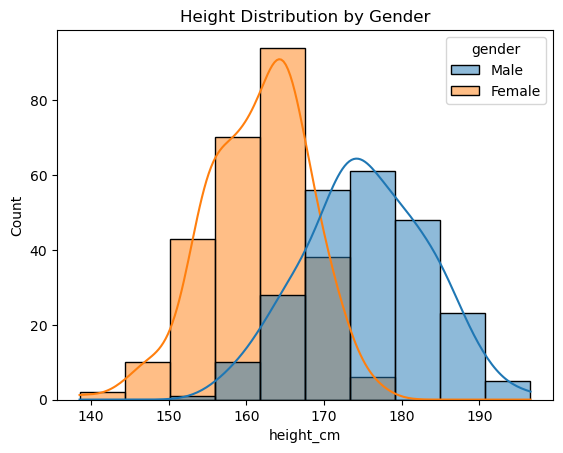

In [89]:
#get distribution of height by gender
sns.histplot(data=df, x='height_cm', hue='gender', kde=True, bins=10)
plt.title('Height Distribution by Gender')
plt.show()

In [90]:
#get skewness analysis
df.groupby('gender')['height_cm'].skew()

gender
Female   -0.363019
Male     -0.022887
Name: height_cm, dtype: float64

Female skewness of -0.363 indicates a mildly left-skewed distribution whereas the
Male skewness of -0.023 indicates an approximately symmetric distribution, very close to zero

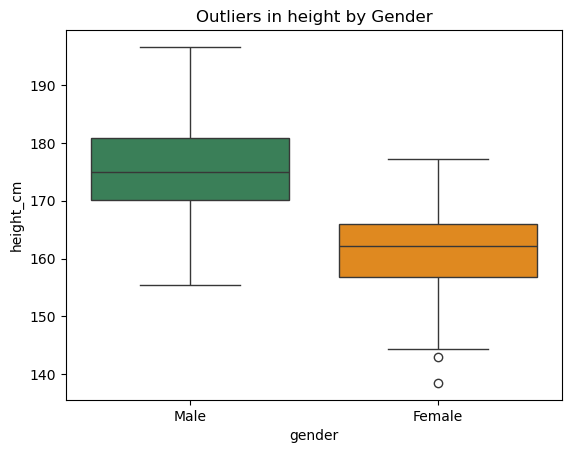

In [91]:
#check for outliers in height by gender
sns.boxplot(data=df, x='gender', y='height_cm', hue='gender', palette={'Male': 'seagreen', 'Female': 'darkorange'})
plt.title('Outliers in height by Gender')
plt.title('Outliers in height by Gender')
plt.show()

In [92]:
#check the female outliers
female_height = df.loc[df['gender'] == 'Female', 'height_cm']

Q1 = female_height.quantile(0.25)
Q3 = female_height.quantile(0.75)

IQR = Q3  - Q1

lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

female_outliers = female_height[(female_height < lower_fence) | (female_height > upper_fence)]

print(female_outliers)

271    138.5
326    143.0
Name: height_cm, dtype: float64


In [93]:
#influence of outliers on the mean

female_without_outliers = female_height[~female_height.isin([138.5, 143.0])]

mean_with_outliers = female_height.mean()
mean_without_outliers = female_without_outliers.mean()

print("Mean with outliers:", mean_with_outliers)
print("Mean without outliers:", mean_without_outliers)

Mean with outliers: 161.493536121673
Mean without outliers: 161.65249042145595


In [94]:
#influence of outliers on median

median_with_outliers = female_height.median()
median_without_outliers = female_without_outliers.median()

print("Median with outliers:", median_with_outliers)
print("Median without outliers:", median_without_outliers)

Median with outliers: 162.2
Median without outliers: 162.2


The two lower outliers in female patients had little influence on the mean, the median was unaffected by their presence. Median imputation would be used to fill the missing height measurements

In [95]:
#create a working dataset from the original dataset
df_working = df.copy()

In [96]:
#fill in the missing values in height column
df_working['height_cm'] = df_working['height_cm'].fillna(df.groupby('gender')['height_cm'].transform('median'))

In [97]:
#check the filled rows
df_working.loc[df[df.isnull().any(axis=1)].index, ['patient_id', 'gender', 'height_cm']]

,patient_id,gender,height_cm
7,PAT-1008,Female,162.2
14,PAT-1015,Male,180.5
42,PAT-1043,Male,174.9
43,PAT-1044,Female,153.7
52,PAT-1053,Female,162.2
65,PAT-1066,Female,162.2
87,PAT-1088,Female,162.2


In [98]:
#get statistical.summary of the working dataframe height by gender
df_working.groupby('gender')['height_cm'].describe()

,count,mean,std,min,25%,50%,75%,max
gender,,,,,,,,
Female,267.0,161.504120,6.481804,138.5,157.0,162.2,165.9,177.3
Male,233.0,175.308584,7.910203,155.5,170.2,174.9,180.9,196.6


Handle missing values in blood type column
-

In [22]:
#get rows with missing values
df[df.isnull().any(axis=1)]

,patient_id,date_of_birth,gender,height_cm,weight_kg,blood_type,systolic_bp_mmHg,diastolic_bp_mmHg,fasting_blood_sugar_mg_dl,cholesterol_mg_dl,daily_salt_intake_g,activity_hours_per_week,smoker_status,hypertension_diagnosis
7,PAT-1008,06/08/2003,Female,NaN,72.5,A+,137,78,109.0,195.5,10.1,0,Non-Smoker,1
14,PAT-1015,08/03/2004,Male,180.5,100.1,NaN,141,84,108.6,192.3,9.7,4,Non-Smoker,1
42,PAT-1043,13/01/1944,Male,NaN,79.1,A+,151,99,132.6,225.1,8.6,5,Non-Smoker,1
43,PAT-1044,19/01/1977,Female,153.7,71.3,NaN,150,86,111.9,199.8,6.2,1,Non-Smoker,1
52,PAT-1053,21/02/1944,Female,NaN,88.4,O+,161,104,115.7,235.2,9.2,2,Former Smoker,1
65,PAT-1066,03/01/1959,Female,NaN,95.7,B+,167,106,122.4,227.9,11.1,2,Current Smoker,1
87,PAT-1088,18/10/1993,Female,NaN,58.8,O+,127,75,85.8,185.7,8.0,0,Non-Smoker,0


Two patients, one male and one female, have missing values in the blood_type column.

In [24]:
#fill the missing values in blood type column with 'Unknown'
df_working['blood_type'] = df_working['blood_type'].fillna('Unknown')

In [25]:
#check the filled rows
df_working.loc[df[df.isnull().any(axis=1)].index, ['patient_id', 'gender', 'blood_type']]

,patient_id,gender,blood_type
7,PAT-1008,Female,A+
14,PAT-1015,Male,Unknown
42,PAT-1043,Male,A+
43,PAT-1044,Female,Unknown
52,PAT-1053,Female,O+
65,PAT-1066,Female,B+
87,PAT-1088,Female,O+


The missing values in the blood_type column were replaced with 'Unknown' rather than the mode, because assigning an unrecorded blood type could introduce clinically significant inaccuracies

In [26]:
#check for missing values in working dataframe
df_working.isnull().sum()

patient_id                   0
date_of_birth                0
gender                       0
height_cm                    0
weight_kg                    0
blood_type                   0
systolic_bp_mmHg             0
diastolic_bp_mmHg            0
fasting_blood_sugar_mg_dl    0
cholesterol_mg_dl            0
daily_salt_intake_g          0
activity_hours_per_week      0
smoker_status                0
hypertension_diagnosis       0
dtype: int64

There are no missing values remaining in the working DataFrame after data cleaning and the handling of missing values.

---

Task 1: Boxplot of cholesterol grouped by smoker_status
-

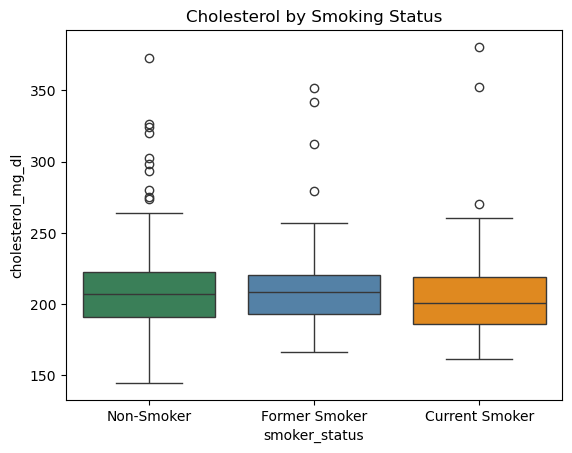

In [66]:
#create the boxplot
sns.boxplot(data=df, x='smoker_status', y='cholesterol_mg_dl', hue='smoker_status', palette={'Current Smoker': 'darkorange', 'Former Smoker': 'steelblue', 'Non-Smoker': 'seagreen'}, legend=False)
plt.title('Cholesterol by Smoking Status')
plt.show()

In [123]:
#calculate, IQR, Q1, and Q3
cholesterol_stats = df_working.groupby('smoker_status')['cholesterol_mg_dl'].agg(
    Q1=lambda x: x.quantile(0.25),
    Median='median',
    Q3=lambda x: x.quantile(0.75))

cholesterol_stats['IQR'] = cholesterol_stats['Q3'] - cholesterol_stats['Q1']

print(cholesterol_stats)

                     Q1  Median       Q3    IQR
smoker_status                                  
Current Smoker  186.225  200.85  219.075  32.85
Former Smoker   192.900  208.10  220.300  27.40
Non-Smoker      190.900  206.70  222.400  31.50


The IQR was highest in current smokers (32.85 mg/dL), this means that cholesterol measurements within the middle 50% of this group were more spread out than those of former smokers (27.40 mg/dL) and non-smokers (31.50 mg/dL). However, the maximum difference between the IQRs was only 5.45 mg/dL, showing similar variability across the three smoking-status groups

In [68]:
#identify the upper whiskers, median lines and count of outliers

for status in df['smoker_status'].unique():
    cholesterol = df.loc[df['smoker_status'] == status, 'cholesterol_mg_dl']
    Q1 = cholesterol.quantile(0.25)
    Q3 = cholesterol.quantile(0.75)

    IQR = Q3  - Q1

    upper_fence = Q3 + 1.5 * IQR

    upper_whisker = cholesterol[cholesterol <= upper_fence].max()

    median_line = cholesterol.median()

    outliers = cholesterol[cholesterol > upper_fence]

    print(status, "Upper whisker:", upper_whisker)
    print(status, "Median line:", median_line)
    print(status, "Upper outlier count:", len(outliers))
    print("-------------------")

Non-Smoker Upper whisker: 264.2
Non-Smoker Median line: 206.7
Non-Smoker Upper outlier count: 10
-------------------
Former Smoker Upper whisker: 257.2
Former Smoker Median line: 208.1
Former Smoker Upper outlier count: 4
-------------------
Current Smoker Upper whisker: 260.1
Current Smoker Median line: 200.85
Current Smoker Upper outlier count: 3
-------------------


Non-smokers had the highest number of upper outliers (10), this shows that more observations in this group had unusually high cholesterol measurements compared with the other observations within the same group.

---

Task 2: Side-by-side box plots of systolic blood pressure by
hypertension diagnosis
-

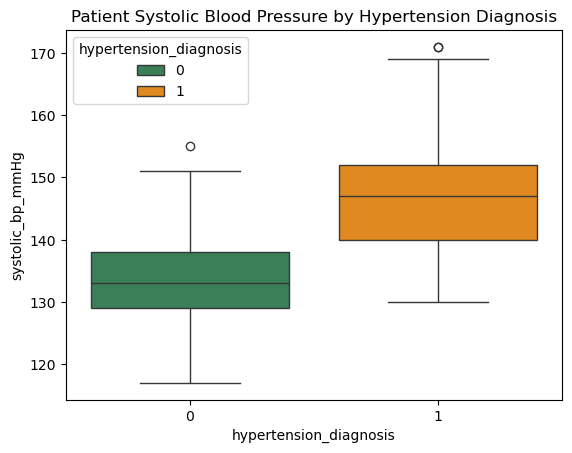

In [31]:
#create a boxplot
sns.boxplot(data=df, x='hypertension_diagnosis', y='systolic_bp_mmHg', hue='hypertension_diagnosis', palette={0: 'seagreen', 1: 'darkorange'})
plt.title('Patient Systolic Blood Pressure by Hypertension Diagnosis')
plt.show()

In [122]:
# Calculate Q1 and Q3 for each hypertension diagnosis group

hypertension_stats = df_working.groupby('hypertension_diagnosis')['systolic_bp_mmHg'].agg(
    Q1=lambda x: x.quantile(0.25),
    Median='median',
    Q3=lambda x: x.quantile(0.75))

hypertension_stats['IQR'] = hypertension_stats['Q3'] - hypertension_stats['Q1']

print(hypertension_stats)

                           Q1  Median     Q3   IQR
hypertension_diagnosis                            
0                       129.0   133.0  138.0   9.0
1                       140.0   147.0  152.0  12.0



The median systolic blood pressure was higher in patients diagnosed with hypertension (147 mmHg) than in those without hypertension (133 mmHg), indicating higher typical systolic BP readings in the hypertension group.

The interquartile ranges IQR did not overlap (129–138 mmHg for patients without hypertension and 140–152 mmHg for patients with hypertension), showing a clear separation between the central systolic BP distributions of the two groups. This separation indicates that systolic BP is a strong feature for distinguishing patients with and without hypertension

--------

Task 3: Factors contributing to hypertension diagnosis of the patients
-

In [104]:
#get date of birth format
df['date_of_birth'].head(1)

0    17/03/1946
Name: date_of_birth, dtype: object

In [102]:
#convert date of birth from object to datetime
df_working['date_of_birth'] = pd.to_datetime(df['date_of_birth'], format='%d/%m/%Y')

In [110]:
#convert date of birth to age

import datetime

def calculate_age(born):
    today = datetime.date.today()
    return today.year - born.year - ((today.month, today.day) < (born.month, born.day))

df_working['age'] = df_working['date_of_birth'].apply(calculate_age)

print(df_working[['patient_id', 'age']])

    patient_id  age
0     PAT-1001   80
1     PAT-1002   34
2     PAT-1003   50
3     PAT-1004   46
4     PAT-1005   30
..         ...  ...
495   PAT-1496   63
496   PAT-1497   81
497   PAT-1498   19
498   PAT-1499   71
499   PAT-1500   81

[500 rows x 2 columns]


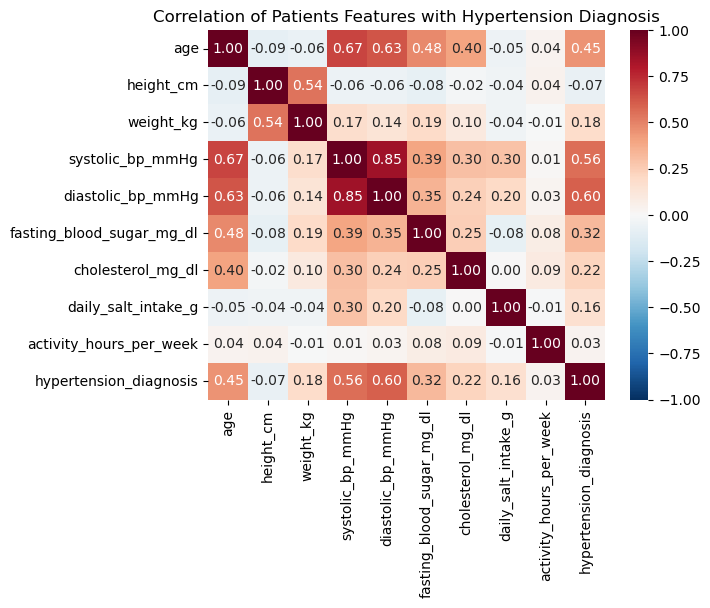

In [121]:
#create correlation heatmap

numeric_columns = [
    'age', 'height_cm', 'weight_kg', 'systolic_bp_mmHg', 
    'diastolic_bp_mmHg', 'fasting_blood_sugar_mg_dl', 'cholesterol_mg_dl', 
    'daily_salt_intake_g', 'activity_hours_per_week', 'hypertension_diagnosis']

corr_matrix = df_working[numeric_columns].corr()

sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation of Patients Features with Hypertension Diagnosis')
plt.show()

The correlation analysis showed that diastolic blood pressure (0.60), systolic blood pressure (0.56) and age (0.45) showed moderate positive correlations with hypertension diagnosis. Fasting blood sugar (0.32), cholesterol (0.22), weight (0.18) and salt intake (0.16) showed weaker positive correlations, while activity hours (0.03) and height (-0.08) showed negligible correlations. Higher blood pressure readings (systolic and diastolic) and increasing age are more strongly associated with hypertension diagnosis


-------

Task 4: Scatterplot of systolic BP vs diastolic BP coloured by
hypertension diagnosis
-

In [37]:
#check correlation between systolic BP and diastolic BP
correlation = df['systolic_bp_mmHg'].corr(df['diastolic_bp_mmHg'])

print(correlation)

0.8494683435068835


The correlation between systolic and diastolic blood pressure is 0.85, a strong positive correlation. This shows that patients with higher systolic BP readings also tend to have higher diastolic BP readings

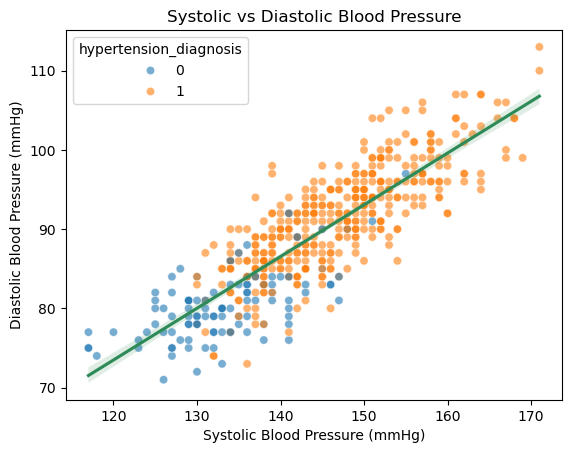

In [38]:
#create scatterplot
sns.scatterplot(data=df_working, x="systolic_bp_mmHg", y="diastolic_bp_mmHg", hue="hypertension_diagnosis", alpha=0.6)

#create trendline
sns.regplot(data=df_working, x="systolic_bp_mmHg", y="diastolic_bp_mmHg", scatter=False, color="seagreen")

plt.title('Systolic vs Diastolic Blood Pressure')
plt.xlabel('Systolic Blood Pressure (mmHg)')
plt.ylabel('Diastolic Blood Pressure (mmHg)')
plt.show()

The trendline slopes upward, indicating that systolic BP increases as diastolic BP increases.
Patients without hypertension cluster mainly in the lower left region. Patients with hypertension cluster mainly in the upper right region 